In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import skfuzzy

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Environment berhasil disiapkan!")

Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
Pandas: 2.3.3
NumPy: 2.2.6
Scikit-learn: 1.9.1
Environment berhasil disiapkan!


In [2]:
# Memuat dataset
df = pd.read_csv(
    "../dataset/laptop_price.csv",
    encoding="latin1"
)

print("Dataset berhasil dimuat!")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

df.head()

Dataset berhasil dimuat!
Jumlah baris: 1303
Jumlah kolom: 13


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


In [3]:
# Informasi struktur dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   object 
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   object 
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB


In [4]:
# Statistik deskriptif
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
laptop_ID,1303.0,NaN,NaN,NaN,660.155794,381.172104,1.0,331.5,659.0,990.5,1320.0
Company,1303,19,Dell,297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1303,618,XPS 13,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TypeName,1303,6,Notebook,727,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inches,1303.0,NaN,NaN,NaN,15.017191,1.426304,10.1,14.0,15.6,15.6,18.4
ScreenResolution,1303,40,Full HD 1920x1080,507,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cpu,1303,118,Intel Core i5 7200U 2.5GHz,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ram,1303,9,8GB,619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,1303,39,256GB SSD,412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gpu,1303,110,Intel HD Graphics 620,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Pemeriksaan missing values
print("Missing Values:")
print(df.isnull().sum())

# Pemeriksaan duplikasi
print("\nJumlah duplikasi seluruh baris:", df.duplicated().sum())

# Pemeriksaan duplikasi berdasarkan spesifikasi laptop
kolom_spesifikasi = [
    col for col in df.columns if col != "laptop_ID"
]

print(
    "Duplikasi tanpa laptop_ID:",
    df.duplicated(subset=kolom_spesifikasi).sum()
)

# Pemeriksaan nilai kosong pada kolom teks
kolom_teks = df.select_dtypes(include="object").columns

print("\nNilai teks kosong:")
print(
    df[kolom_teks]
    .apply(lambda col: col.str.strip().eq("").sum())
)

Missing Values:
laptop_ID           0
Company             0
Product             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price_euros         0
dtype: int64

Jumlah duplikasi seluruh baris: 0
Duplikasi tanpa laptop_ID: 28

Nilai teks kosong:
Company             0
Product             0
TypeName            0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
dtype: int64


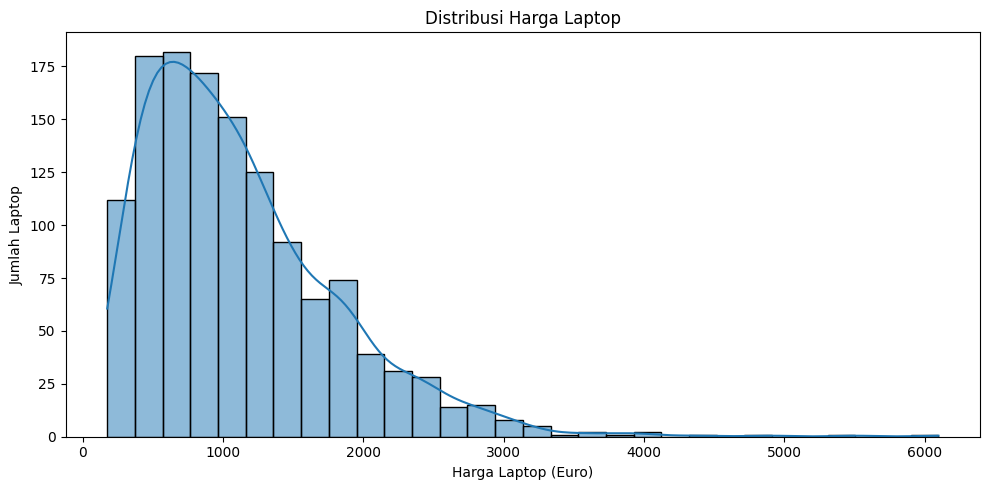

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Price_euros",
    bins=30,
    kde=True
)

plt.title("Distribusi Harga Laptop")
plt.xlabel("Harga Laptop (Euro)")
plt.ylabel("Jumlah Laptop")

plt.tight_layout()
plt.show()

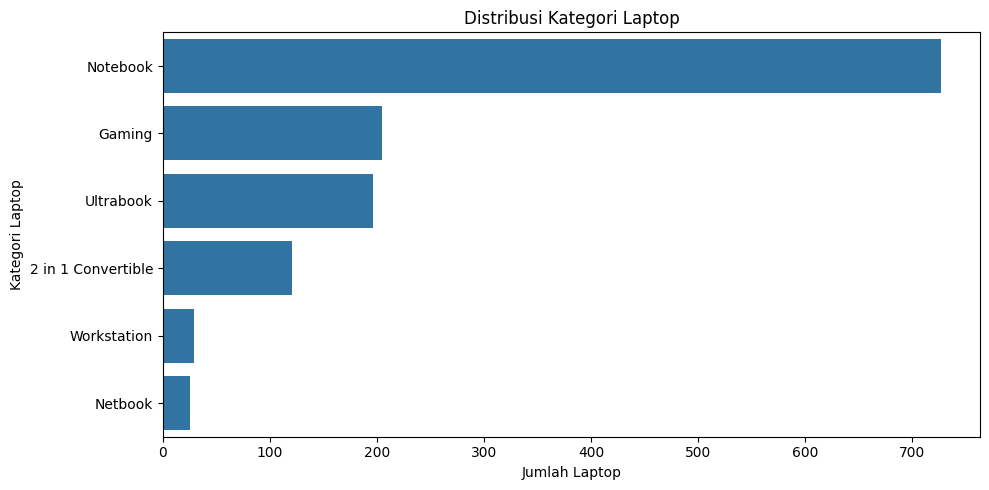

In [7]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y="TypeName",
    order=df["TypeName"].value_counts().index
)

plt.title("Distribusi Kategori Laptop")
plt.xlabel("Jumlah Laptop")
plt.ylabel("Kategori Laptop")

plt.tight_layout()
plt.show()